# Weather Hazard Category: XGBoost experiment

Student **25945320**. Predicts the Weather Hazard Category at **+7 days** from the leakage-audited feature
matrix built by the preprocessing notebook.

## Hypothesis

Gradient-boosted trees will achieve the highest validation macro F1 of the five hazard
experiments, because boosting concentrates successive rounds on the examples the ensemble is
currently getting wrong — which on a severely imbalanced target means the rare hazard days.

The competing possibility is the more likely one and is stated first in the report: with only a
few dozen minority-class training days, boosting has very little to concentrate on, and the
configuration that maximises macro F1 on a validation split containing a handful of such days may
be selected by noise. The seed-stability check in section 5 is the test, and a negative result
there is a finding rather than a failure.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `XGBClassifier`, `hist`, softmax objective | Strong tabular performance; handles the ordinal classes as nominal, which section 6 examines |
| Imbalance | Balanced sample weights, tuned on and off | Whether re-weighting helps is an empirical question, not a default |
| Scaling | None | Trees split on thresholds |
| Tuning | Optuna TPE, 20 trials | Nine interacting hyperparameters including the weighting switch |
| Objective | Validation macro F1, maximised | Accuracy would select a majority-class predictor (see section 5) |

## Notebook structure

All ten experiment notebooks in this project follow the same ten sections and share their
machinery through `modeling.experiment` in the custom package, so results are directly
comparable and a change to a metric or a baseline applies everywhere at once.

| Section | Contents |
|---|---|
| 1 | Load the chronological splits (train and validation only) |
| 2 | Baselines |
| 3 | Model specification and default configuration |
| 4 | Feature-group ablation |
| 5 | Optuna hyperparameter optimisation |
| 6 | Final model and evaluation |
| 7 | Feature attribution |
| 8 | Generalisation check |
| 9 | Saved artefacts |
| 10 | Conclusions |

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)


def _project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = _project_root()
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling import experiment as xp  # noqa: E402  (path must be set first)

RANDOM_STATE = 25945320
# Trial count is overridable so the notebook can be smoke-tested quickly:
#   OPTUNA_TRIALS=5 jupyter nbconvert --execute ...
N_TRIALS = int(os.environ.get("OPTUNA_TRIALS", "30"))
SEED_CHECK = (RANDOM_STATE, 7, 2024)

EXPERIMENT = "whc_xgboost"
ALGORITHM_NAME = "XGBoost Classifier"
MODEL_LABEL = "xgboost"
MODEL_FAMILY = "xgboost"

task = xp.load_task("weather_hazard")
print(f"Task      : {task.target_name} ({task.kind})")
print(f"Experiment: {EXPERIMENT} - {ALGORITHM_NAME}")
print(f"Features  : {len(task.feature_columns)} across {len(task.feature_groups)} families")
print(f"Targets   : {', '.join(task.target_columns)}")
print(f"Optuna    : {N_TRIALS} trials per study, seed {RANDOM_STATE}")
print("\nRuntime note: the trial count is deliberately modest so the notebook completes in "
      "minutes\nrather than hours. Raise it with OPTUNA_TRIALS=100 once the notebook is known "
      "to run, and\nread the seed-stability table in section 5 before treating any extra trials "
      "as progress.")

Task      : Weather Hazard Category (classification)
Experiment: whc_xgboost - XGBoost Classifier
Features  : 105 across 8 families
Targets   : whc_t7
Optuna    : 30 trials per study, seed 25945320

Runtime note: the trial count is deliberately modest so the notebook completes in minutes
rather than hours. Raise it with OPTUNA_TRIALS=100 once the notebook is known to run, and
read the seed-stability table in section 5 before treating any extra trials as progress.


## 1. Load the chronological splits

Only the training and validation files are read. **The test split is never loaded in this
notebook.** It is reserved for a single final evaluation once one model has been selected across
all experiments, so that no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
embargo at each boundary. Nothing is re-split or shuffled. Features and targets live in separate
files and are aligned by the `feature_date` index, which `load_xy` verifies on every read.

In [2]:
X, y = {}, {}
for split in ("train", "val"):
    X[split], y[split] = task.load_xy(split)

if X["train"].index.max() >= X["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for split in ("train", "val"):
    print(f"{split:5} {len(X[split]):5,} rows  {X[split].index.min():%Y-%m-%d} to "
          f"{X[split].index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")


TARGET = task.target_columns[0]
# Classes are remapped to contiguous codes for fitting and decoded straight back, so every
# algorithm receives labels in the form it expects and reports labels in the brief's numbering.
LABELS = xp.OrdinalLabels(y["train"][TARGET])
METRIC_LABELS = list(LABELS.classes_)          # averaged over by the objective
REPORT_LABELS = sorted(task.class_labels)      # all four brief classes, for the confusion matrix

print(f"\nTarget: {TARGET}")
print("Training class distribution:")
print(y["train"][TARGET].value_counts().sort_index()
      .rename(index=task.class_labels).to_string())
print("Validation class distribution:")
print(y["val"][TARGET].value_counts().sort_index()
      .rename(index=task.class_labels).to_string())
missing = [task.class_labels[c] for c in REPORT_LABELS if c not in METRIC_LABELS]
if missing:
    print(f"\nNot present in training and therefore not predictable: {missing}")
    print("These are excluded from the macro average but still shown in the confusion matrix.")
if not LABELS.contiguous:
    print(f"Classes {LABELS.classes_} remapped to contiguous codes for fitting.")

train 2,885 rows  2016-01-31 to 2023-12-24
val     359 rows  2024-01-01 to 2024-12-24

Test split deliberately not loaded.

Target: whc_t7
Training class distribution:
whc_t7
Low Risk         1450
Moderate Risk    1315
High Risk         113
Extreme Risk        7
Validation class distribution:
whc_t7
Low Risk         165
Moderate Risk    178
High Risk         16


## 2. Baselines

Three reference forecasts. With one hazard class holding the overwhelming majority of days, a
model that fails to beat these is not merely unimpressive — it is almost certainly just
predicting the majority class in a more expensive way.

**Majority class** always predicts the most frequent training class. Its accuracy is high and its
macro F1 is poor, which is exactly why accuracy is not used as the objective.

**Persistence** carries the hazard class observed on day *t* forward to *t*+7. The class at *t* is
not itself a feature, but it follows directly from the `whi` feature by applying the brief's
thresholds, so the rule needs no extra inputs.

**Seasonal mode** predicts the most common class for that calendar month in the training period.
It encodes the seasonal base rate and nothing else.

In [3]:
BASELINE_PREDICTIONS = xp.classification_baselines(task, X, y)

rows = []
for label, prediction in BASELINE_PREDICTIONS.items():
    rows.append({"model": label,
                 **xp.classification_metrics(y["val"][TARGET], prediction, METRIC_LABELS)})
BASELINES = pd.DataFrame(rows).set_index("model")
BASELINE_F1 = BASELINES["macro_f1"].max()

print("Validation baselines (the floors any model must clear):\n")
print(BASELINES.to_string())
print(f"\nBest baseline macro F1: {BASELINE_F1:.4f}")
print(f"Macro F1 of a perfect majority-class rule is bounded by "
      f"{1 / len(METRIC_LABELS):.3f} when only one class is ever predicted.")

Validation baselines (the floors any model must clear):

                accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                
majority_class     0.460              0.333     0.157        0.289         0.250            0.115               0.585
persistence        0.429              0.298     0.224        0.428         0.224            0.224               0.621
seasonal_mode      0.549              0.385     0.280        0.533         0.289            0.278               0.482

Best baseline macro F1: 0.2796
Macro F1 of a perfect majority-class rule is bounded by 0.250 when only one class is ever predicted.


## 3. Model specification and default configuration

Everything specific to this algorithm lives in the next cell: how the estimator is built, the
default configuration, and the search space Optuna will sample. Every other section of this
notebook is shared with the other experiments, so a reader comparing two notebooks can diff this
one cell and know exactly what differs.

The default configuration is fitted and scored before any tuning. It is the reference against
which the Optuna result in section 6 is judged — a search that fails to improve on a sensible
default is a result worth reporting, not a step to skip.

In [4]:
# The estimator is module-scoped so exported Joblib bundles can be loaded outside this notebook.
BalancedXGBClassifier = xp.BalancedXGBClassifier


def build_estimator(params: dict, seed: int = RANDOM_STATE) -> BalancedXGBClassifier:
    """Build a classifier from a parameter dictionary."""
    return BalancedXGBClassifier(**{
        "tree_method": "hist", "n_jobs": -1, "random_state": seed, "verbosity": 0,
        "objective": "multi:softprob", **params
    })


DEFAULT_PARAMS = {
    "n_estimators": 400, "learning_rate": 0.05, "max_depth": 4, "min_child_weight": 3,
    "subsample": 0.8, "colsample_bytree": 0.6, "reg_lambda": 1.0, "reg_alpha": 0.0,
    "balance_classes": True,
}
ABLATION_PARAMS = {**DEFAULT_PARAMS, "n_estimators": 150, "learning_rate": 0.08}


def suggest_params(trial) -> dict:
    """Sample one candidate configuration.

    ``balance_classes`` is the parameter to watch. Without it the booster can minimise its loss by
    predicting the majority class everywhere, which scores well on accuracy and badly on the
    macro F1 being optimised; with it, the rare days are up-weighted at the cost of false alarms.
    ``min_child_weight`` interacts directly with that switch, because balanced weights inflate the
    effective weight of minority rows and change what counts as a viable leaf.
    """
    return {
        "n_estimators": trial.suggest_int("n_estimators", 150, 700, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "min_child_weight": trial.suggest_float("min_child_weight", 0.5, 20.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.5, 50.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 5.0, log=True),
        "balance_classes": trial.suggest_categorical("balance_classes", [True, False]),
    }

In [5]:
def fit_model(params: dict, columns: list[str] | None = None, seed: int = RANDOM_STATE):
    """Fit one classifier and return it with its decoded predictions per split."""
    columns = columns or task.feature_columns
    model = build_estimator(params, seed)
    model.fit(X["train"][columns], LABELS.encode(y["train"][TARGET]))
    predictions = {split: LABELS.decode(model.predict(X[split][columns]))
                   for split in ("train", "val")}
    return model, predictions


default_model, default_predictions = fit_model(DEFAULT_PARAMS)
DEFAULTS = pd.DataFrame([{
    "model": f"{MODEL_LABEL} (default)",
    **xp.classification_metrics(y["val"][TARGET], default_predictions["val"], METRIC_LABELS),
}]).set_index("model")

print("Validation performance with the default configuration:\n")
print(DEFAULTS.to_string())
print(f"\nMacro F1 against the best baseline: "
      f"{DEFAULTS['macro_f1'].iloc[0] - BASELINE_F1:+.4f}")
print("\nPredicted class distribution (a model predicting one class only is a majority rule):")
print(pd.Series(default_predictions["val"]).value_counts().sort_index()
      .rename(index=task.class_labels).to_string())

Validation performance with the default configuration:

                   accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                   
xgboost (default)     0.515              0.361     0.263        0.502         0.271            0.261               0.515

Macro F1 against the best baseline: -0.0163

Predicted class distribution (a model predicting one class only is a majority rule):
Low Risk         207
Moderate Risk    151
High Risk          1


## 4. Feature-group ablation

The preprocessing notebook recorded which engineered family each column belongs to. Families are
added cumulatively and the model refitted at each step, so the contribution of each block of
engineering is measured rather than assumed.

The sequence starts from persistence alone — a single column, today's hazard index — and builds
up. A family that does not move validation macro F1 is not earning its place in the deployed
model.

Two cautions specific to this task. Macro F1 on a validation split containing only a handful of
minority-class days moves in visible steps, so small differences between adjacent configurations
should not be over-read. And a family can *lower* macro F1 while raising accuracy, by giving the
model enough capacity to collapse onto the majority class; the accuracy column is printed
alongside so that behaviour is visible rather than hidden.

Default hyperparameters are used throughout, so differences are attributable to the feature set
rather than to tuning.

Validation scores by cumulative feature set (macro F1: higher is better):

                         n_features  macro_f1  balanced_accuracy  accuracy  mean_ordinal_error
config                                                                                        
persistence only (whi)            1     0.213              0.280     0.345               0.811
+ same_day_observations           6     0.263              0.368     0.448               0.624
+ same_day_indices               17     0.254              0.346     0.443               0.627
+ lags                           49     0.244              0.324     0.465               0.591
+ rolling_statistics             89     0.260              0.349     0.501               0.549
+ rolling_precipitation          93     0.272              0.366     0.526               0.515
+ rolling_gusts                  97     0.251              0.341     0.487               0.546
+ deltas                        103     0.247              0.338     0

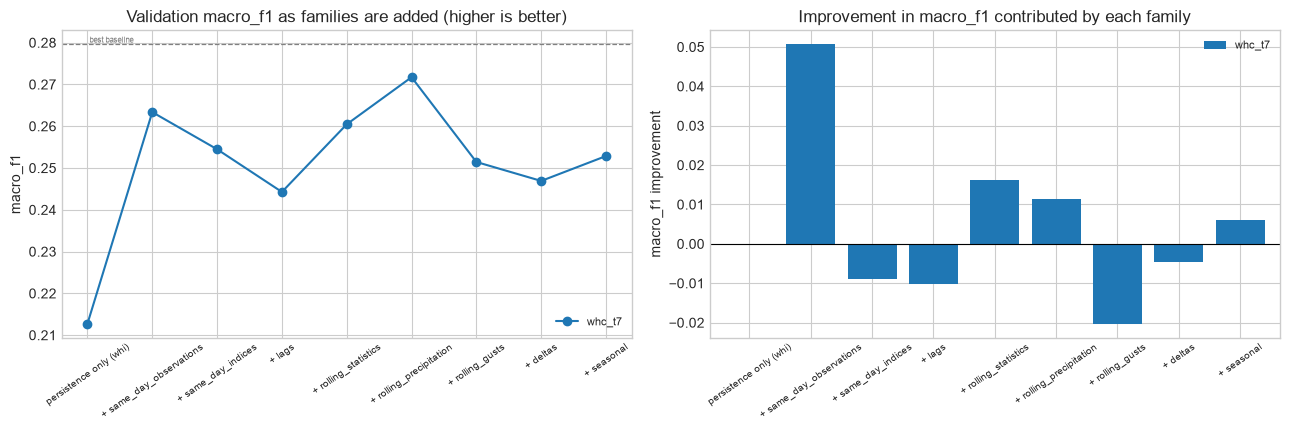

In [6]:
ABLATION_CONFIGS = xp.cumulative_feature_sets(task)


def ablation_score(columns: list[str], target: str) -> dict[str, float]:
    """Fit the default configuration on one feature subset and score it on validation."""
    _, predictions = fit_model(ABLATION_PARAMS, columns)
    return xp.classification_metrics(y["val"][target], predictions["val"], METRIC_LABELS)


ABLATION = xp.run_ablation(ABLATION_CONFIGS, ablation_score, [TARGET])
fig, ABLATION_F1 = xp.plot_ablation(
    task, ABLATION, "macro_f1", [TARGET], f"{EXPERIMENT}-ablation",
    higher_is_better=True, reference={"best baseline": BASELINE_F1},
)
summary = ABLATION.set_index("config")[["n_features", "macro_f1", "balanced_accuracy",
                                        "accuracy", "mean_ordinal_error"]]
print("Validation scores by cumulative feature set (macro F1: higher is better):\n")
print(summary.to_string())
plt.show()

## 5. Hyperparameter optimisation with Optuna

### Which metric is optimised, and why

The objective is **macro-averaged F1 on the validation split**, maximised.

*Why not accuracy.* The class distribution reported during preprocessing is severely imbalanced —
one class holds the overwhelming majority of days. A model that predicts that class for every row
scores very well on accuracy while being operationally worthless, because the whole point of a
hazard service is to flag the unusual days. Optimising accuracy would actively select for that
degenerate model.

*Why macro F1 rather than balanced accuracy.* Balanced accuracy is macro-averaged recall, so it
rewards catching minority-class days and is blind to how many false alarms that costs. On a
target where High Risk days are rare, a model can reach high balanced accuracy by flagging
hazards liberally, which would make the endpoint untrustworthy. Macro F1 averages the harmonic
mean of precision and recall across classes, so a configuration must both find the rare days and
be right when it claims one. Balanced accuracy is still reported at every step, so the trade-off
is visible.

*Why not a cost-weighted metric.* Weighting a miss against a false alarm would be more faithful
to how a transport or events operator actually experiences the error, but the weights would be
invented rather than elicited. Macro F1 is the defensible choice absent a real cost matrix, and
the confusion matrix in section 6 lets a stakeholder apply their own weights to the raw counts.

*Which classes are averaged over.* Only the classes present in the **training** split. A class the
model has never seen cannot be predicted, and including it would add a fixed zero to every
configuration's macro average, compressing the differences the search is trying to detect. The
confusion matrix in section 6 still displays all four brief classes, so an absent class is
visible as an empty row rather than quietly dropped.

*Why validation and not cross-validation.* The split is chronological by design. A shuffled
k-fold would place future days in the training folds and inflate every score, because consecutive
days are strongly autocorrelated. The fixed 2024 validation period preserves the temporal
ordering and matches how the deployed model will be used.

### The optimism this introduces, and a specific warning

Validation data selects the hyperparameters and then reports the performance of the selection, so
the reported macro F1 is slightly better than a truly unseen estimate. The honest final estimate
comes from the test split, which no notebook in this project has touched.

This matters more here than for the regression task. Macro F1 on a validation period containing
only a handful of minority-class days is a high-variance statistic: reclassifying two days can
move it substantially. The seed-stability check below is therefore not a formality. If refitting
the selected hyperparameters under different random seeds moves macro F1 by as much as the gap
between the best and tenth-best trial, the search has been ranking noise, and the report should
say so rather than presenting the selected configuration as meaningfully better.

In [7]:
from sklearn.metrics import f1_score


def objective(trial) -> float:
    """Maximise validation macro F1 over the classes observed in training."""
    params = suggest_params(trial)
    model = build_estimator(params, RANDOM_STATE)
    model.fit(X["train"], LABELS.encode(y["train"][TARGET]))
    prediction = LABELS.decode(model.predict(X["val"]))
    return float(f1_score(y["val"][TARGET], prediction, labels=METRIC_LABELS,
                          average="macro", zero_division=0))


STUDIES = {TARGET: xp.optimise(objective, n_trials=N_TRIALS, direction="maximize",
                               seed=RANDOM_STATE, study_name=f"{EXPERIMENT}_{TARGET}")}
study = STUDIES[TARGET]
frame = xp.study_frame(study)
BEST_PARAMS = {**DEFAULT_PARAMS, **study.best_params}

print(f"Best validation macro F1 {study.best_value:.4f} from trial {study.best_trial.number} "
      f"({len(frame)} completed trials)")
print(f"Best params: {study.best_params}")
print(f"Improvement over the best baseline: {study.best_value - BASELINE_F1:+.4f}")
print("\nTop five trials:\n")
print(frame.head(5).to_string(index=False))

/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Best validation macro F1 0.2758 from trial 27 (30 completed trials)
Best params: {'n_estimators': 500, 'learning_rate': 0.01004833010673823, 'max_depth': 4, 'min_child_weight': 7.698017339536525, 'subsample': 0.694804765649022, 'colsample_bytree': 0.33248437236972506, 'reg_lambda': 7.226674613678695, 'reg_alpha': 0.003653357436394771, 'balance_classes': False}
Improvement over the best baseline: -0.0038

Top five trials:

 trial  value  n_estimators  learning_rate  max_depth  min_child_weight  subsample  colsample_bytree  reg_lambda  reg_alpha  balance_classes
    27  0.276           500          0.010          4             7.698      0.695             0.332       7.227      0.004            False
    21  0.276           650          0.014          2            15.216      0.744             0.414       2.624      0.004            False
    28  0.274           500          0.012          3            18.336      0.719             0.305       6.986      0.011            False
    29  0.

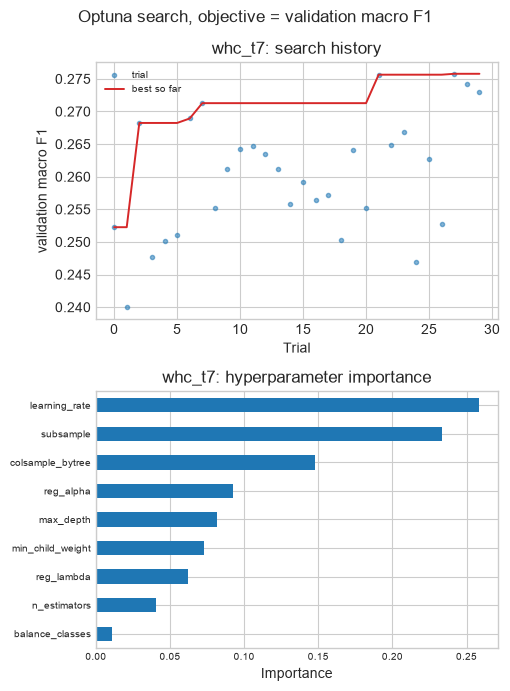

Seed-stability check (see the notes above for how to read `search_beats_noise`):

        best_trial_macro_f1  seed_mean  seed_spread  top10_trial_spread  search_beats_noise
target                                                                                     
whc_t7                0.276      0.271        0.011               0.011               False


In [8]:
xp.plot_optuna(task, STUDIES, "validation macro F1", f"{EXPERIMENT}-optuna")
plt.show()

frame = xp.study_frame(STUDIES[TARGET])
top_spread = float(frame["value"].head(10).max() - frame["value"].head(10).min())
seed_values = []
for seed in SEED_CHECK:
    _, predictions = fit_model(BEST_PARAMS, seed=seed)
    seed_values.append(float(f1_score(y["val"][TARGET], predictions["val"],
                                      labels=METRIC_LABELS, average="macro", zero_division=0)))

STABILITY = pd.DataFrame([{
    "target": TARGET,
    "best_trial_macro_f1": STUDIES[TARGET].best_value,
    "seed_mean": float(np.mean(seed_values)),
    "seed_spread": float(np.max(seed_values) - np.min(seed_values)),
    "top10_trial_spread": top_spread,
    "search_beats_noise": float(np.max(seed_values) - np.min(seed_values)) < top_spread,
}]).set_index("target")
print("Seed-stability check (see the notes above for how to read `search_beats_noise`):\n")
print(STABILITY.to_string())

## 6. Final model and evaluation against the baselines

The selected hyperparameters are refitted and scored against all three baselines and against the
default configuration, so the notebook reports what tuning actually bought.

The confusion matrix is the most informative output in this notebook and belongs in the report.
It shows all four brief classes, including any that never occur, and it lets a reader apply their
own view of the relative cost of a missed hazard versus a false alarm — something no single
summary metric can express.

`mean_ordinal_error` exploits the fact that the classes are ordered. Predicting Low Risk when the
truth is Extreme is a worse failure than predicting Moderate, and a plain classification metric
cannot see that difference.

The class timeline plots the predicted and observed classes across 2024 with the underlying WHI
overlaid. Errors clustered near a class boundary are a different problem from errors made deep
inside a class: the first is a thresholding artefact of a continuous index being cut into bands,
the second is a genuine failure to read the weather.

Validation performance:

                   accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
model                                                                                                                   
xgboost               0.540              0.379     0.276        0.526         0.284            0.272               0.485
xgboost (default)     0.515              0.361     0.263        0.502         0.271            0.261               0.515
majority_class        0.460              0.333     0.157        0.289         0.250            0.115               0.585
persistence           0.429              0.298     0.224        0.428         0.224            0.224               0.621
seasonal_mode         0.549              0.385     0.280        0.533         0.289            0.278               0.482

Macro F1 gain over each reference (positive means the tuned model is better):

                   reference_macro_f1  macro_f1_

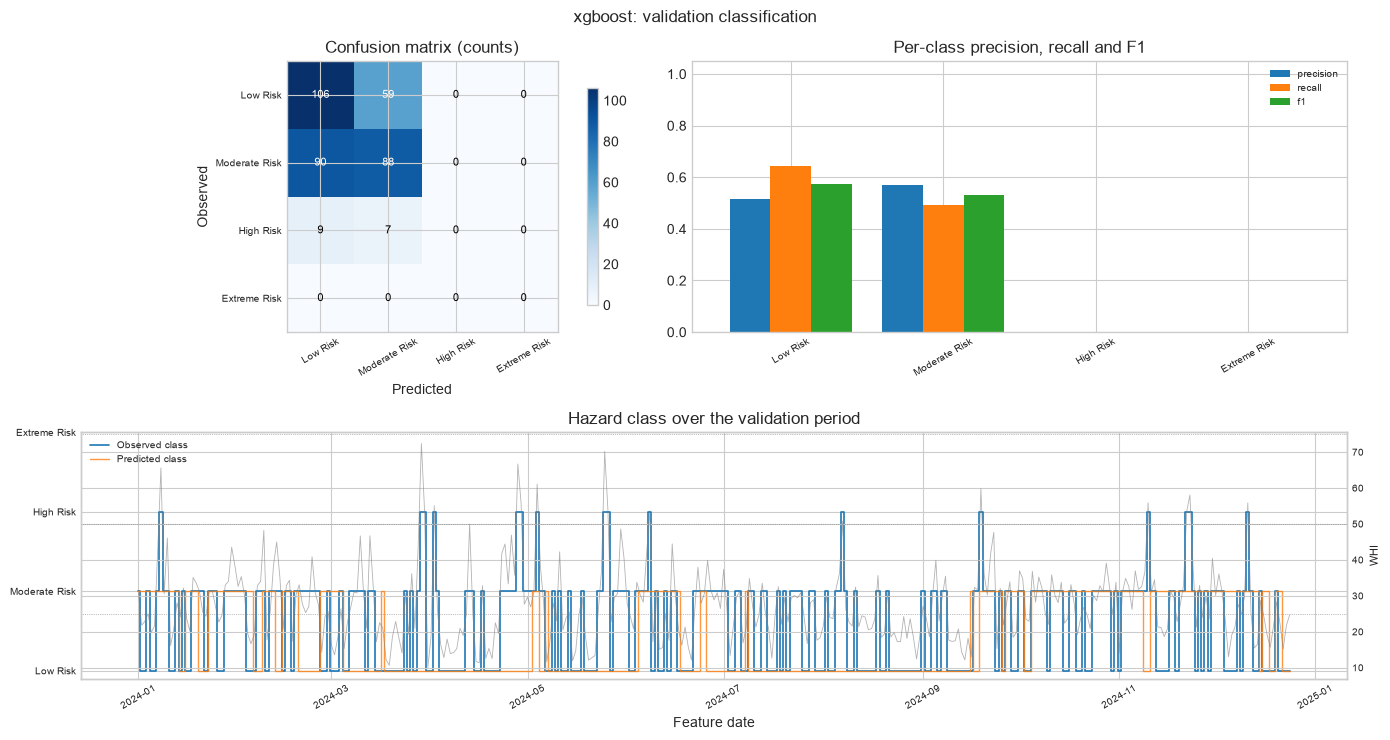


Misclassified days: 165 of 359
  median distance from the nearest class boundary: 5.1 WHI points
  share within 5 WHI points of a boundary: 48.5%


In [9]:
model, predictions = fit_model(BEST_PARAMS)
models = {TARGET: model}
VAL_PREDICTION = predictions["val"]
TRAIN_PREDICTION = predictions["train"]

rows = [
    {"model": MODEL_LABEL,
     **xp.classification_metrics(y["val"][TARGET], VAL_PREDICTION, METRIC_LABELS)},
    {"model": f"{MODEL_LABEL} (default)",
     **xp.classification_metrics(y["val"][TARGET], default_predictions["val"], METRIC_LABELS)},
]
for label, prediction in BASELINE_PREDICTIONS.items():
    rows.append({"model": label,
                 **xp.classification_metrics(y["val"][TARGET], prediction, METRIC_LABELS)})
RESULTS = pd.DataFrame(rows).set_index("model")
print("Validation performance:\n")
print(RESULTS.to_string())

tuned_f1 = RESULTS.loc[MODEL_LABEL, "macro_f1"]
comparison = pd.DataFrame([{
    "reference": reference,
    "reference_macro_f1": RESULTS.loc[reference, "macro_f1"],
    "macro_f1_gain": tuned_f1 - RESULTS.loc[reference, "macro_f1"],
} for reference in RESULTS.index if reference != MODEL_LABEL]).set_index("reference")
print("\nMacro F1 gain over each reference (positive means the tuned model is better):\n")
print(comparison.to_string())

AUX = task.load_aux("val")
fig, PER_CLASS = xp.plot_classification_validation(
    task, X["val"].index, y["val"][TARGET], VAL_PREDICTION, REPORT_LABELS,
    MODEL_LABEL, f"{EXPERIMENT}-validation", whi=AUX[task.auxiliary_columns[0]],
)
print("\nPer-class validation performance (all four brief classes shown):\n")
print(PER_CLASS.to_string())
plt.show()

# Errors near a class boundary are a thresholding artefact; errors deep inside a class are not.
errors = VAL_PREDICTION != y["val"][TARGET].to_numpy()
if errors.any():
    distance = AUX[task.auxiliary_columns[0]].to_numpy()[errors]
    boundary_distance = np.min(np.abs(distance[:, None] - np.array([25, 50, 75])), axis=1)
    print(f"\nMisclassified days: {int(errors.sum())} of {len(errors)}")
    print(f"  median distance from the nearest class boundary: "
          f"{np.median(boundary_distance):.1f} WHI points")
    print(f"  share within 5 WHI points of a boundary: "
          f"{float(np.mean(boundary_distance < 5)):.1%}")

## 7. Feature attribution

Impurity-based importances are read from the fitted model and exported for the `/model-metadata`
endpoint.

Two caveats govern how these should be read. First, many of these features are strongly
correlated — a variable, its four lags and its four rolling means all carry nearly the same
signal — and tree ensembles split that shared importance among the group, so an individually
unimportant-looking feature may be part of a jointly essential block.

Second, and specific to this task: impurity importance is computed over all splits in the
ensemble, which on a severely imbalanced target is dominated by the splits that separate the
majority class. A feature that is decisive for identifying rare hazard days can therefore rank
low. The per-class results in section 6 are the better guide to whether the rare classes are
being detected at all.

Total importance by family:

                       whc_t7
family                       
deltas                  0.049
lags                    0.293
rolling_gusts           0.044
rolling_precipitation   0.037
rolling_statistics      0.395
same_day_indices        0.096
same_day_observations   0.055
seasonal                0.031

Share of total importance held by the top 10 features: 12.9%


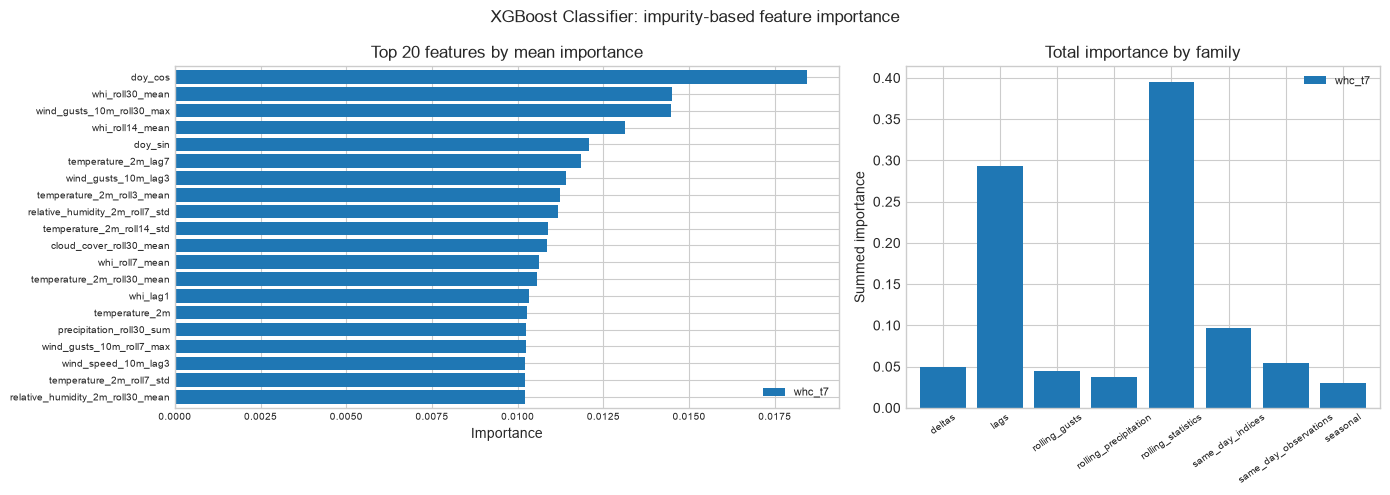

In [10]:
IMPORTANCES = pd.DataFrame(
    {TARGET: pd.Series(models[TARGET].feature_importances_, index=task.feature_columns)}
)
fig, FAMILY_TOTALS = xp.plot_importance(
    task, IMPORTANCES, f"{EXPERIMENT}-importance",
    f"{ALGORITHM_NAME}: impurity-based feature importance",
)
print("Total importance by family:\n")
print(FAMILY_TOTALS.to_string())
share = IMPORTANCES[TARGET].nlargest(10).sum() / IMPORTANCES[TARGET].sum()
print(f"\nShare of total importance held by the top 10 features: {share:.1%}")
plt.show()

## 8. Generalisation check

Training and validation performance side by side. For an imbalanced classification task the
informative comparison is macro F1, not accuracy: accuracy will look similar on both splits
simply because the majority class dominates each of them.

Read this together with the seed-stability table in section 5. A model with a wide train-to-
validation macro F1 gap *and* a large seed spread is fitting noise, which on a target with this
few minority-class examples is the expected failure mode rather than a surprising one.

In [11]:
gap_rows = []
for split, prediction in (("train", TRAIN_PREDICTION), ("val", VAL_PREDICTION)):
    gap_rows.append({"split": split,
                     **xp.classification_metrics(y[split][TARGET], prediction, METRIC_LABELS)})
GAP = pd.DataFrame(gap_rows).set_index("split")
print(GAP.to_string())

print("\nTrain-to-validation change:")
for metric in ("macro_f1", "balanced_accuracy", "accuracy"):
    print(f"  {metric:<18} {GAP.loc['train', metric]:.4f} -> {GAP.loc['val', metric]:.4f} "
          f"({GAP.loc['val', metric] - GAP.loc['train', metric]:+.4f})")

print("\nPredicted class distribution by split:")
print(pd.DataFrame({
    "train": pd.Series(TRAIN_PREDICTION).value_counts(),
    "val": pd.Series(VAL_PREDICTION).value_counts(),
}).reindex(REPORT_LABELS).fillna(0).astype(int)
  .rename(index=task.class_labels).to_string())

       accuracy  balanced_accuracy  macro_f1  weighted_f1  macro_recall  macro_precision  mean_ordinal_error
split                                                                                                       
train     0.758              0.394     0.386        0.741         0.394            0.379               0.262
val       0.540              0.379     0.276        0.526         0.284            0.272               0.485

Train-to-validation change:
  macro_f1           0.3861 -> 0.2758 (-0.1103)
  balanced_accuracy  0.3941 -> 0.3789 (-0.0152)
  accuracy           0.7581 -> 0.5404 (-0.2177)

Predicted class distribution by split:
               train  val
Low Risk        1622  205
Moderate Risk   1263  154
High Risk          0    0
Extreme Risk       0    0


## 9. Saved artefacts

The fitted classifier is written together with a metadata document shaped for the
`/model-metadata` endpoint: target, algorithm, forecast horizon, feature list, feature importance,
selected hyperparameters, class labels and validation metrics.

The metadata records the exact feature column order. The API must construct its feature vector in
that order, since the estimator receives an unnamed array at prediction time and will silently
produce wrong answers if the columns are permuted. It also records the class-code mapping, which
the endpoint needs in order to return `"Moderate Risk"` rather than `1`.

The test split remains unused.

In [12]:
model_entries = [{
    "target": task.target_name,
    "target_column": TARGET,
    "prediction_type": "multiclass_classification",
    "algorithm": ALGORITHM_NAME,
    "forecast_horizon": f"{task.horizons[0]} Days",
    "hyperparameters": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                        for k, v in BEST_PARAMS.items()},
    "features": task.feature_columns,
    "feature_importance": {
        column: float(value) for column, value
        in IMPORTANCES[TARGET].sort_values(ascending=False).head(20).items()
    } if not IMPORTANCES.empty else {},
    "classes_trained": [int(c) for c in LABELS.classes_],
    "class_names": {str(c): task.class_labels[c] for c in LABELS.classes_},
    "validation_metrics": RESULTS.loc[MODEL_LABEL].to_dict(),
    "per_class_validation": PER_CLASS.reset_index().to_dict(orient="records"),
    "baseline_metrics": {reference: RESULTS.loc[reference].to_dict()
                         for reference in BASELINE_PREDICTIONS},
}]

METADATA = xp.build_metadata(
    task, EXPERIMENT, ALGORITHM_NAME, model_entries,
    best_params={k: str(v) for k, v in BEST_PARAMS.items()},
    extra={
        "optimisation": {
            "library": "optuna",
            "objective": "validation macro-averaged F1 over classes seen in training",
            "direction": "maximize",
            "trials_per_study": N_TRIALS,
            "classes_averaged": [int(c) for c in METRIC_LABELS],
        },
        "seed_stability": STABILITY.reset_index().to_dict(orient="records"),
        "class_imbalance_note": (
            "Accuracy is not a meaningful selection metric for this target; macro F1 and the "
            "confusion matrix are the reportable results."
        ),
    },
)
bundle = xp.export_experiment(task, EXPERIMENT, models, METADATA, MODEL_FAMILY)
print(f"Saved bundle: {bundle.relative_to(PROJECT_ROOT)}")
print("\nThe test split has still not been touched. It should be used exactly once, after a")
print("single model has been selected on validation performance across all experiments.")

Saved bundle: models/weather_hazard/experiments/whc_xgboost

The test split has still not been touched. It should be used exactly once, after a
single model has been selected on validation performance across all experiments.


## 10. Conclusions

- **Did re-weighting win?** Compare the top trials with `balance_classes` true and false. This is
  the most decision-relevant hyperparameter in the notebook, because it encodes an operational
  stance on missed hazards versus false alarms.
- **Read the confusion matrix, not the headline.** A macro F1 that beats the baselines while the
  matrix shows the rare classes almost never predicted means the gain came from the majority
  classes and the service still cannot flag a hazardous day.
- **Boundary errors.** The share of misclassifications within a few WHI points of a class
  threshold, printed in section 6, separates a thresholding artefact from a genuine failure to
  read the weather. A high share argues for predicting WHI and thresholding afterwards, which is
  a concrete recommendation for future work.

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all ten experiment notebooks.